In [65]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime
from scipy.interpolate import make_interp_spline
from matplotlib.ticker import FuncFormatter
import seaborn as sns

In [66]:
plt.rcParams['font.sans-serif'] = 'Roboto'   # Specific font name
plt.rcParams['font.size'] = 12              # Default text size in points
plt.rcParams['font.style'] = 'normal'       # Options: normal, italic, oblique
plt.rcParams['font.weight'] = 'normal'      # Options: normal, bold, etc.
plt.rcParams["lines.linewidth"] = 3.0  # Set global default line width

In [67]:
df = pd.read_csv("../datasets/sales_data_cln.csv").copy()

In [68]:
df.columns

Index(['user_id', 'order_id', 'purchase_ts', 'ship_ts', 'refund_ts',
       'product_name', 'product_id', 'usd_price', 'purchase_platform',
       'marketing_channel', 'account_creation_method', 'country_code',
       'purchase_y', 'purchase_ym', 'purchase_ymd', 'purchase_ymw',
       'purchase_q', 'ship_y', 'ship_ym', 'ship_ymd', 'ship_ymw', 'ship_q'],
      dtype='object')

In [69]:
df["marketing_channel"].unique()

array(['affiliate', 'direct', 'email', 'social media', 'organic',
       'unknown'], dtype=object)

In [70]:
df["purchase_platform"].unique()

array(['website', 'mobile app'], dtype=object)

In [71]:
co = df[df["refund_ts"].isna()]

marketing_data_q = co.groupby(["purchase_q", "marketing_channel"]).agg(total_revenue=("usd_price", "sum"), total_orders = ("order_id", "count")).reset_index()

In [72]:
marketing_data_q

,purchase_q,marketing_channel,total_revenue,total_orders
0,2019Q1,affiliate,17475.49,62
1,2019Q1,direct,217980.31,1002
2,2019Q1,email,20410.73,121
3,2019Q1,social media,3802.59,27
4,2019Q1,unknown,336.00,2
5,2019Q2,affiliate,9367.20,49
6,2019Q2,direct,280521.96,1209
7,2019Q2,email,23291.85,141
8,2019Q2,social media,4439.71,24
9,2019Q3,affiliate,19716.40,76


In [73]:
pivot_df = marketing_data_q.pivot_table(
    index="purchase_q", columns="marketing_channel", values="total_revenue")

pivot_df = pivot_df.reindex(["direct", "email", "affiliate", "social media", "organic", "uknown"], axis = 1)

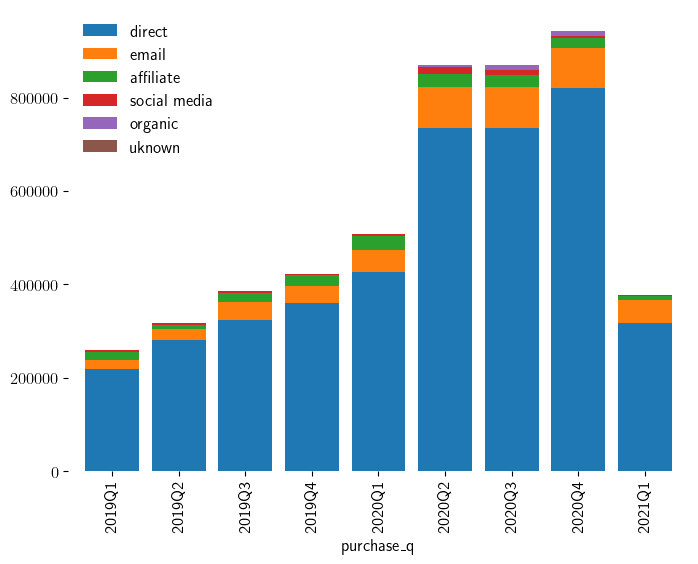

In [74]:
ax = pivot_df.plot(
    kind='bar',
    stacked=True,
    edgecolor='none',
    figsize=(8, 6),
    width = 0.81
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)
# ax.axes.get_xaxis().set_visible(False)
# ax.axes.get_yaxis().set_visible(False)



ax.legend(frameon = False)

<Axes: xlabel='purchase_q'>

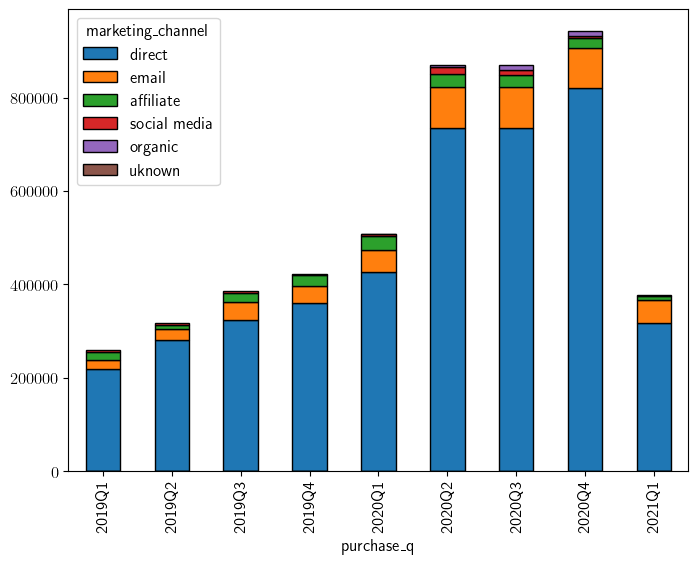

In [75]:
pivot_df.plot.bar(stacked=True, figsize=(8, 6), edgecolor="black")

